<a href="https://colab.research.google.com/github/Aditya-Nand/IBM-Data-Analytics-AI-Project/blob/main/adityanand_retailsalesanalytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales Analytics with AI
**Author:** Aditya Nand  
**Track:** Data Analytics with AI  
**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn

## Project objective
Explore retail transaction data, clean it, identify sales patterns, visualise key metrics, and create a simple baseline model to estimate sales amount from available numeric features.

## Dataset
Download the Retail Sales Dataset from Kaggle:
https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset

After downloading, place the CSV file in the same folder as this notebook. If the filename differs, update `DATA_FILE` in the next cell. Do not upload private customer data.


In [ ]:
# If needed in Google Colab/Jupyter, install dependencies first:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

sns.set_theme()
pd.set_option("display.max_columns", 50)

DATA_FILE = "retail_sales_dataset.csv"  # Change this to the exact downloaded CSV filename


In [ ]:
# Load dataset. If the CSV is not found, stop with a clear message.
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"Could not find '{DATA_FILE}'. Download the Kaggle dataset, place its CSV beside this notebook, "
        "and update DATA_FILE to match the filename."
    )

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


## 1. Data quality checks
The dataset may use slightly different column names. The next cell normalises names and detects common retail fields.

In [ ]:
# Standardise column names for easier processing
df.columns = [
    str(c).strip().lower().replace(" ", "_").replace("-", "_").replace("/", "_")
    for c in df.columns
]

print("Standardised columns:", df.columns.tolist())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values").head(15))
print("Duplicate rows:", int(df.duplicated().sum()))

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

def find_column(candidates, columns):
    for candidate in candidates:
        if candidate in columns:
            return candidate
    return None

date_col = find_column(["date", "order_date", "transaction_date", "invoice_date"], df.columns)
sales_col = find_column(["total_amount", "sales", "revenue", "amount", "total_sales"], df.columns)
qty_col = find_column(["quantity", "qty", "units_sold"], df.columns)
price_col = find_column(["price_per_unit", "unit_price", "price"], df.columns)
category_col = find_column(["product_category", "category", "product_type"], df.columns)
product_col = find_column(["product_name", "product", "item_name", "description"], df.columns)

# Derive sales if there is no total amount column but quantity and unit price are available
if sales_col is None and qty_col and price_col:
    df[qty_col] = pd.to_numeric(df[qty_col], errors="coerce")
    df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
    df["calculated_sales"] = df[qty_col] * df[price_col]
    sales_col = "calculated_sales"

if sales_col is None:
    raise ValueError(
        "Could not identify a sales/amount column. Check the dataset columns and set sales_col manually."
    )

df[sales_col] = pd.to_numeric(df[sales_col], errors="coerce")
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce", dayfirst=True)

df = df.dropna(subset=[sales_col]).copy()
print("Rows after basic cleaning:", len(df))
print("Sales column:", sales_col, "| Date column:", date_col, "| Category column:", category_col)
display(df.head())


Standardised columns: ['transaction_id', 'date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']


,missing_values
transaction_id,0
date,0
customer_id,0
gender,0
age,0
product_category,0
quantity,0
price_per_unit,0
total_amount,0


Duplicate rows: 0
Rows after basic cleaning: 1000
Sales column: total_amount | Date column: date | Category column: product_category


,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 2. Summary statistics
We calculate total sales, average transaction value, and sales distribution. These are descriptive analytics, not proof of causation.

Total sales / amount: 456,000.00
Average transaction amount: 456.00
Median transaction amount: 135.00


,sales_summary
count,1000.000000
mean,456.000000
std,559.997632
min,25.000000
25%,60.000000
50%,135.000000
75%,900.000000
max,2000.000000


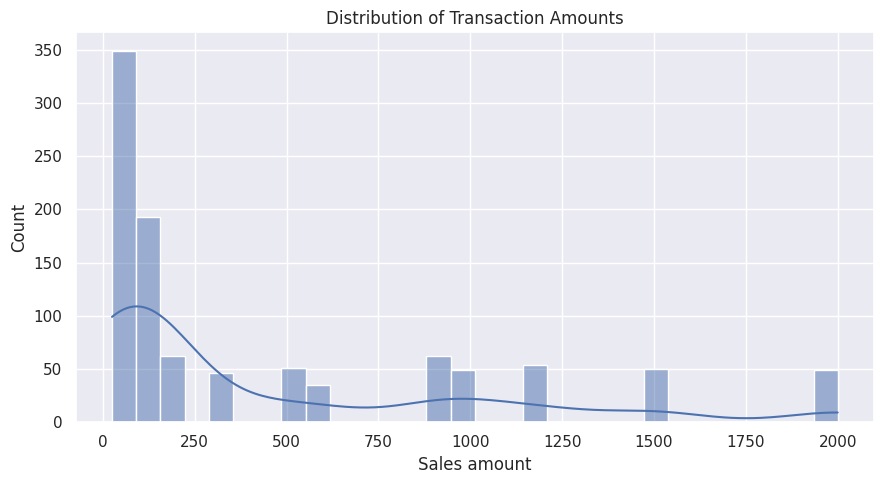

In [ ]:
total_sales = df[sales_col].sum()
average_sale = df[sales_col].mean()
median_sale = df[sales_col].median()

print(f"Total sales / amount: {total_sales:,.2f}")
print(f"Average transaction amount: {average_sale:,.2f}")
print(f"Median transaction amount: {median_sale:,.2f}")
display(df[sales_col].describe().to_frame("sales_summary"))

plt.figure(figsize=(9, 5))
sns.histplot(df[sales_col].dropna(), bins=30, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Sales amount")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## 3. Category analysis
If a category field exists, compare sales totals by category.

,total_sales
product_category,
Electronics,156905
Clothing,155580
Beauty,143515


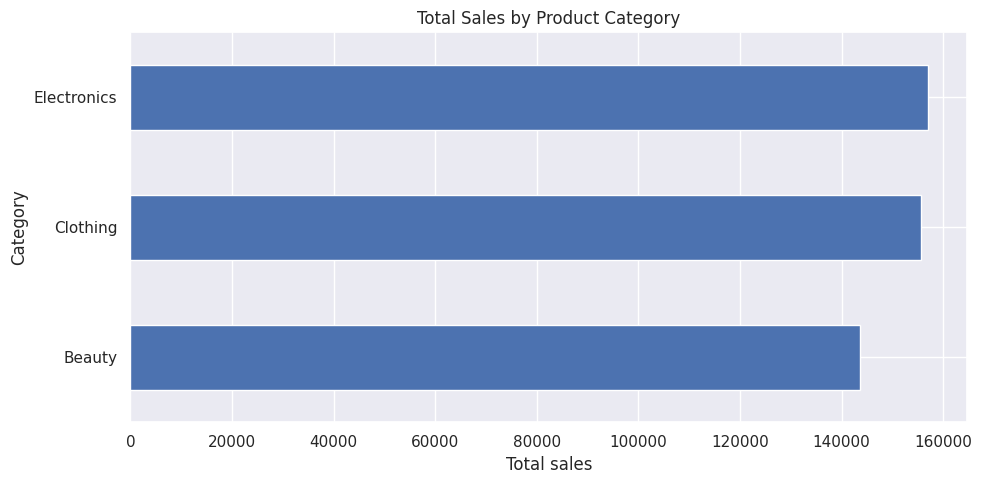

In [ ]:
if category_col:
    category_sales = (
        df.groupby(category_col, dropna=False)[sales_col]
        .sum()
        .sort_values(ascending=False)
        .head(15)
    )
    display(category_sales.to_frame("total_sales"))

    plt.figure(figsize=(10, 5))
    category_sales.sort_values().plot(kind="barh")
    plt.title("Total Sales by Product Category")
    plt.xlabel("Total sales")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()
else:
    print("No recognised category column found. Skip category analysis or set category_col manually.")


## 4. Time trend analysis
If a date column exists, aggregate sales by month and visualise the trend.

,monthly_sales
month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


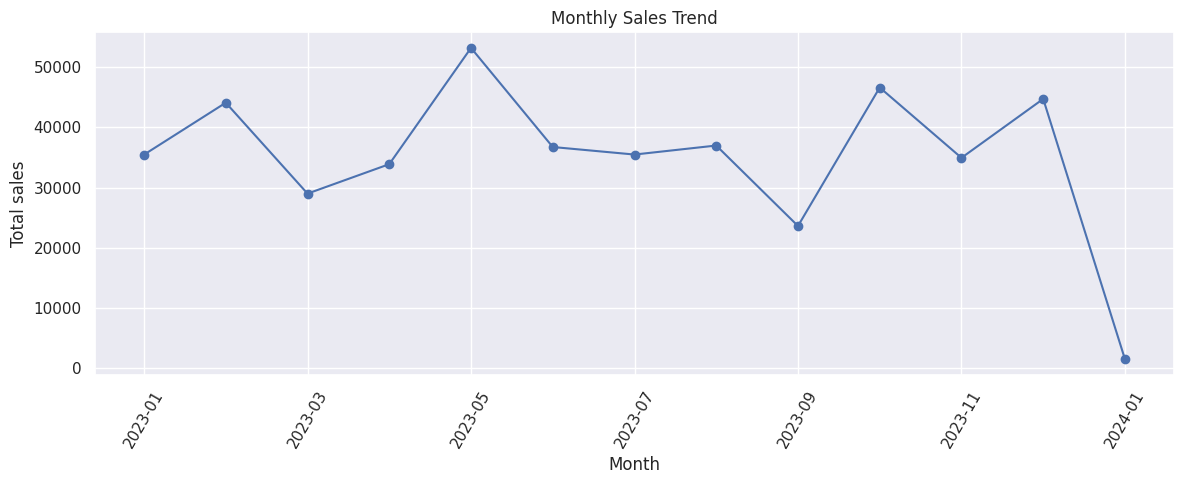

In [ ]:
if date_col:
    time_df = df.dropna(subset=[date_col]).copy()
    time_df["month"] = time_df[date_col].dt.to_period("M").astype(str)
    monthly_sales = time_df.groupby("month")[sales_col].sum().sort_index()

    display(monthly_sales.to_frame("monthly_sales").tail(24))
    plt.figure(figsize=(12, 5))
    monthly_sales.plot(marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total sales")
    plt.xticks(rotation=60)
    plt.tight_layout()
    plt.show()
else:
    print("No recognised date column found. Skip time trend analysis or set date_col manually.")


## 5. Simple AI/ML baseline
A Random Forest regression model estimates transaction amount from other available fields. This is a baseline demonstration, not a production forecasting system. The target sales column is excluded from the input features to prevent leakage.

Features used: ['quantity', 'price_per_unit', 'product_category', 'gender', 'age']
MAE:  0.000
RMSE: 0.000
R²:   1.000


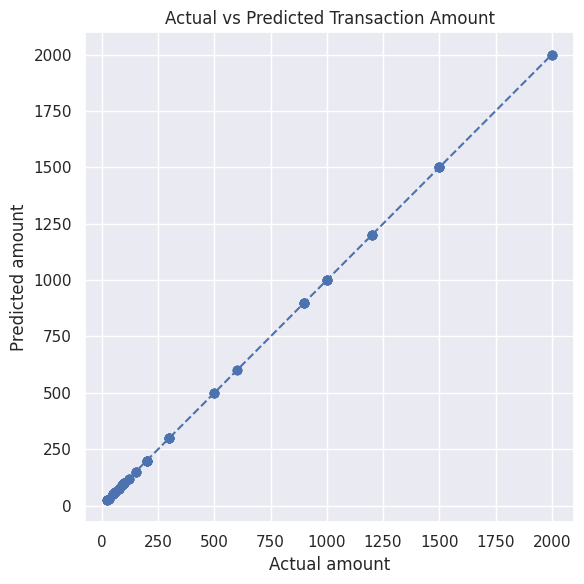

In [ ]:
# Select useful input columns that exist in this dataset
candidate_features = [
    c for c in [qty_col, price_col, category_col, product_col]
    if c is not None and c in df.columns and c != sales_col
]
# Include other low-cardinality categorical or numeric columns, excluding IDs and the target
for c in df.columns:
    if c == sales_col or c in candidate_features or c == date_col:
        continue
    if any(token in c for token in ["id", "invoice", "customer"]):
        continue
    if pd.api.types.is_numeric_dtype(df[c]) or df[c].nunique(dropna=True) <= 30:
        candidate_features.append(c)

candidate_features = list(dict.fromkeys(candidate_features))
model_df = df[candidate_features + [sales_col]].copy() if candidate_features else pd.DataFrame()

if len(candidate_features) == 0 or len(model_df) < 20:
    print("Not enough suitable feature columns/rows for a meaningful model. Complete the analytics sections above.")
else:
    X = model_df[candidate_features]
    y = model_df[sales_col]

    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X.columns if c not in numeric_features]

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = []
    if numeric_features:
        transformers.append(("num", numeric_transformer, numeric_features))
    if categorical_features:
        transformers.append(("cat", categorical_transformer, categorical_features))

    preprocessor = ColumnTransformer(transformers=transformers)
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print("Features used:", candidate_features)
    print(f"MAE:  {mae:,.3f}")
    print(f"RMSE: {rmse:,.3f}")
    print(f"R²:   {r2:,.3f}")

    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, predictions, alpha=0.6)
    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())
    plt.plot([low, high], [low, high], linestyle="--")
    plt.title("Actual vs Predicted Transaction Amount")
    plt.xlabel("Actual amount")
    plt.ylabel("Predicted amount")
    plt.tight_layout()
    plt.show()


## 6. Export cleaned data and key findings
The following cell saves a cleaned copy and creates a small text summary that you can use in the project report. Verify the outputs after running the notebook.

In [ ]:
cleaned_file = "retail_sales_cleaned.csv"
df.to_csv(cleaned_file, index=False)
print(f"Saved cleaned dataset to: {cleaned_file}")

findings = [
    f"Rows analysed: {len(df):,}",
    f"Total sales/amount: {df[sales_col].sum():,.2f}",
    f"Average transaction amount: {df[sales_col].mean():,.2f}",
    f"Median transaction amount: {df[sales_col].median():,.2f}",
]
if category_col:
    top_category = df.groupby(category_col)[sales_col].sum().sort_values(ascending=False)
    if len(top_category):
        findings.append(f"Top category by sales: {top_category.index[0]} ({top_category.iloc[0]:,.2f})")
if date_col:
    dated = df.dropna(subset=[date_col]).copy()
    if len(dated):
        dated["month"] = dated[date_col].dt.to_period("M").astype(str)
        monthly = dated.groupby("month")[sales_col].sum().sort_values(ascending=False)
        if len(monthly):
            findings.append(f"Highest-sales month in this dataset: {monthly.index[0]} ({monthly.iloc[0]:,.2f})")

print("\nKEY FINDINGS")
for item in findings:
    print("-", item)


Saved cleaned dataset to: retail_sales_cleaned.csv

KEY FINDINGS
- Rows analysed: 1,000
- Total sales/amount: 456,000.00
- Average transaction amount: 456.00
- Median transaction amount: 135.00
- Top category by sales: Electronics (156,905.00)
- Highest-sales month in this dataset: 2023-05 (53,150.00)


## Conclusion
This project demonstrates a repeatable analytics workflow: load data, inspect quality, clean records, summarise sales, visualise category/time trends, and evaluate a basic regression model. Report actual metrics and insights produced by your run; do not invent results. The model's quality depends on the dataset and the available features.